# 05 · Modelos de retenciones: ¿qué explica los defectos del Skinpass?

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 4 (modelado), problema B

## A. Contexto de la etapa

**¿Qué investigamos?** La parte B de la tesis: una vez controlado por producto, ¿en qué medida la herencia del MC4, frente a las condiciones del Skinpass, explica que una pieza se **retenga por un defecto físico**?

**Resultados** (definiciones aprobadas el 2026-11-28):
- **B1:** retención por regla automática (o por una medición registrada por un inspector).
- **B2:** defecto físico observado por un inspector, por familias: forma, enrollado, superficie y manejo (metalúrgico y bordes tienen muy pocos eventos).
- **Administrativa** (retenida solo por peso): se analiza aparte, como evidencia para la intervención A.

**Lo que traemos de los notebooks anteriores:**
- **Notebook 02:** las piezas con defecto de forma tenían **mucha más fuerza real** y más corona.
- **Notebook 04:** el esfuerzo depende poco del MC4 y mucho del operador y de la campaña.

Si los defectos siguen el mismo patrón, la intervención está en la operación del Skinpass. Si los defectos sí dependen del MC4, la herencia actúa por otra vía que no es el esfuerzo.

## B. Fundamento conceptual

**1. Clasificación con eventos raros.** B2 · forma ocurre en ~0.3 % de las piezas. Con eso, un modelo que diga "nunca hay defecto" acierta el 99.7 % de las veces: la **exactitud** no sirve. Usamos:
- **PR-AUC (precisión promedio):** resume qué tan bien el modelo pone a las piezas con defecto arriba de la lista. Su valor "de azar" es la tasa base (por ejemplo 0.003), así que la reportamos también como **mejora sobre el azar** (PR-AUC / tasa base).
- **ROC-AUC:** probabilidad de que una pieza con defecto reciba un puntaje mayor que una sin defecto. 0.5 es azar.
- **Brier score y Brier skill:** error cuadrático de la probabilidad predicha, comparado contra predecir siempre la tasa base. El skill positivo indica probabilidades útiles.

**2. No reponderamos clases.** Dar más peso a los eventos raros mejora algunas métricas, pero deforma las probabilidades. Como el objetivo es entender y estimar riesgos, dejamos las probabilidades sin deformar y medimos con métricas que ya consideran el desbalance.

**3. Modelos anidados con un bloque más: el esfuerzo.** El esfuerzo (fuerza y bending reales, sus Δ) ocurre **durante** el Skinpass, después de la herencia del MC4. En el problema B es el posible **mediador**:

| Modelo | Bloques |
|---|---|
| M1 | Controles (producto, dimensiones, orden, modo del Skinpass) |
| M2 | + MC4 |
| M3 | + Skinpass (rodillos, operador, preset) |
| M4 | + MC4 + Skinpass |
| M5 | M4 + esfuerzo (mediador) |

Si el MC4 aporta en M2 pero ese aporte desaparece en M5, la herencia actuaría **a través del esfuerzo**. El análisis formal de mediación es del Notebook 06.

**4. Regresión logística como línea base.** Modelo lineal para la probabilidad (en escala log-odds). Es interpretable: cada coeficiente se convierte en un **odds ratio**, cuánto se multiplica la "probabilidad relativa" del defecto por cada desviación estándar de la variable. El producto, con ~800 niveles, entra como **tasa histórica del producto** calculada fuera de pliegue (codificación por objetivo) para no filtrar información.

**5. Tasa observada contra esperada (O/E).** Para comparar operadores sin que influya el producto que procesan: para cada pieza, la tasa esperada es la del producto; O/E = defectos observados / defectos esperados. O/E = 1.5 significa 50 % más defectos de lo que su mezcla de productos haría esperar.

## C. Objetivo y metodología

1. **Tasas base** de cada resultado, y por modo del Skinpass, comparando dentro de producto.
2. **GBDT anidados M1-M5** con validación por programa MC4 y por campaña: PR-AUC, mejora sobre el azar, ROC-AUC, Brier skill.
3. **Regresión logística** para B2 · forma con las variables de la hipótesis del mediador (odds ratios).
4. **Forma de la relación** entre fuerza real (dentro de producto) y la tasa de defectos de forma.
5. **Operador** y defectos (O/E).
6. **Administrativa:** cuántas retenciones por PESO (+) se habrían evitado dividiendo los rollos que exceden la orden (insumo para la intervención A).

**Población:** todas las piezas ligadas del **entrenamiento** (enero-octubre). La prueba final sigue sin tocarse. Para B1 no se usan los días de espera (pueden ser consecuencia, Notebook 03).

## D. Implementación
### 0. Configuración

In [1]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        # La copia de Colab es desechable: se iguala a GitHub aunque tenga figuras o archivos regenerados.
        subprocess.run(['git', '-C', REPO, 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', REPO, 'reset', '-q', '--hard', 'origin/main'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [2]:
import sys, warnings
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.model_selection import GroupKFold
import statsmodels.api as sm
from src.ternium import *

warnings.filterwarnings('ignore', category=UserWarning)
estilo()
pd.set_option('display.max_columns', 30, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)
SEMILLA = 2025

In [3]:
B = cargar_base_analitica()
d = B[~B['en_prueba']].reset_index(drop=True)
print(f"Entrenamiento: {len(d):,} piezas · {d['producto'].nunique()} productos")

CONTROLES = ['espesor_mm', 'ancho_mm', 'espesor_final_nominal_mm', 'peso_entrada_t', 'dividido', 'es_reproceso',
             'holgura_peso_pct', 'modo_fuerza']
d['modo_fuerza'] = (d['modo'] == 'Fuerza').astype(int)
MC4 = ['corona_relativa_pct', 'acunamiento_um', 'taper_medido', 'error_espesor_um', 'error_ancho_mm', 'posicion_tol_ancho',
       'canteo_r1', 'canteo_r2', 'offset_ancho_manual_aplicado', 'error_t_enrollado_c', 'enrollado_frio', 'enrollado_fuera_rango',
       'error_t_acabado_c', 't_f1_c', 'caida_f1_f7_c', 'asimetria_acabador_c', 'looper_media_mpa', 'looper_max_mpa',
       't_descarga_horno_c', 'tiempo_estancia_horno', 'cubierta_termica_pct', 'dias_mc4_skp']
SKP = ['piezas_en_campana', 'diametro_rodillo_mm', 'dif_diametro_pareja_mm', 'corona_rodillo', 'diametro_apoyo_sup_mm',
       'riesgo_spring_back', 'preset_fuerza', 'preset_bending', 'usuario_skp']
ESFUERZO = ['fuerza_real', 'bending_real', 'delta_fuerza', 'delta_bending', 'elongacion']
RESULT = {'b1': 'B1 · regla', 'b2': 'B2 · inspector', 'b2_forma': 'B2 · forma', 'b2_enrollado': 'B2 · enrollado',
          'b2_superficie_manejo': 'B2 · superficie'}
for c in ['producto', 'usuario_skp']:
    d[c] = d[c].astype('category')

tasas = pd.DataFrame({'eventos': d[list(RESULT)].sum(), 'tasa %': 100 * d[list(RESULT)].mean(),
                      'tasa % modo Elongación': 100 * d.loc[d.modo_fuerza == 0, list(RESULT)].mean(),
                      'tasa % modo Fuerza': 100 * d.loc[d.modo_fuerza == 1, list(RESULT)].mean()}).rename(index=RESULT)
tasas.round(3)

Entrenamiento: 47,461 piezas · 773 productos


,eventos,tasa %,tasa % modo Elongación,tasa % modo Fuerza
B1 · regla,1246,2.625,2.481,4.089
B2 · inspector,558,1.176,0.967,3.290
B2 · forma,136,0.287,0.236,0.799
B2 · enrollado,206,0.434,0.343,1.363
B2 · superficie,163,0.343,0.324,0.541


**¿El modo Fuerza tiene más defectos por el modo o por los productos que procesa?** Comparamos la tasa observada en modo Fuerza contra la esperada según sus productos (O/E).

In [4]:
def oe(df, resultado, grupo):
    esperado = df.groupby('producto', observed=True)[resultado].transform('mean')
    t = df.assign(e=esperado).groupby(grupo, observed=True).agg(piezas=(resultado, 'size'), observados=(resultado, 'sum'),
                                                                esperados=('e', 'sum'))
    t['O/E'] = t.observados / t.esperados
    return t

pd.concat({RESULT[r]: oe(d, r, 'modo')['O/E'] for r in RESULT}, axis=1).round(2)

,B1 · regla,B2 · inspector,B2 · forma,B2 · enrollado,B2 · superficie
modo,,,,,
Elongación,0.94,0.84,0.77,0.87,0.90
Fuerza,1.70,2.31,7.93,1.59,3.27


### 1. GBDT anidados M1-M5
Clasificador LightGBM con parámetros conservadores (hojas con al menos 200 piezas) para no memorizar los pocos eventos. Probabilidades fuera de pliegue con validación por **programa MC4** y por **campaña**.

In [5]:
PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=5.0, random_state=SEMILLA, verbose=-1)
pl_mc4 = d['pliegue'].values
pl_camp = np.zeros(len(d), int)
for k, (_, va) in enumerate(GroupKFold(n_splits=5).split(d, groups=d['campana'])):
    pl_camp[va] = k

# B1 es una regla sobre mediciones: no se usan como predictores las mediciones que la definen (tautología, Notebook 00),
# ni los días de espera (pueden ser consecuencia de la retención, Notebook 03).
DEFINEN_B1 = ['error_ancho_mm', 'posicion_tol_ancho', 'error_espesor_um', 'error_t_enrollado_c', 'enrollado_frio',
              'enrollado_fuera_rango', 'dias_mc4_skp', 'elongacion']

def bloques(resultado, clave, permitir_tautologia=False):
    excluir = DEFINEN_B1 if (resultado == 'b1' and not permitir_tautologia) else []
    cols = ['producto'] + CONTROLES
    if 'M' in clave: cols += MC4
    if 'S' in clave: cols += SKP
    if 'E' in clave: cols += ESFUERZO
    return [c for c in cols if c not in excluir]

def prob_oof(resultado, cols, pliegues):
    p = np.full(len(d), np.nan)
    for k in range(5):
        tr, va = pliegues != k, pliegues == k
        p[va] = lgb.LGBMClassifier(**PARAMS).fit(d.loc[tr, cols], d.loc[tr, resultado]).predict_proba(d.loc[va, cols])[:, 1]
    return p

def metricas(y, p):
    base = y.mean()
    return {'PR-AUC': average_precision_score(y, p), 'mejora sobre azar ×': average_precision_score(y, p) / base,
            'ROC-AUC': roc_auc_score(y, p), 'Brier skill %': 100 * (1 - brier_score_loss(y, p) / brier_score_loss(y, np.full_like(p, base)))}

MODELOS = {'M1 controles': 'C', 'M2 + MC4': 'CM', 'M3 + Skinpass': 'CS', 'M4 MC4 + Skinpass': 'CMS', 'M5 + esfuerzo': 'CMSE'}
filas, prob = [], {}
for r in RESULT:
    y = d[r].values
    for nombre, clave in MODELOS.items():
        for val, pl in [('programa MC4', pl_mc4), ('campaña', pl_camp)]:
            p = prob_oof(r, bloques(r, clave), pl); prob[(r, nombre, val)] = p
            filas.append({'resultado': RESULT[r], 'modelo': nombre, 'validación': val, **metricas(y, p)})
# Comparación didáctica: B1 con las variables que definen la regla (lo que NO debe hacerse).
p_taut = prob_oof('b1', bloques('b1', 'CM', permitir_tautologia=True), pl_camp)
fila_taut = {'resultado': RESULT['b1'], 'modelo': 'M2 + MC4 CON las variables de la regla', 'validación': 'campaña',
             **metricas(d['b1'].values, p_taut)}
tab = pd.DataFrame(filas)
tab.round(4).to_csv(RESULTADOS / '05_gbdt_anidados.csv', index=False)
print('B1 con tautología (no válido):', {k: round(v, 3) for k, v in fila_taut.items() if k not in ('resultado', 'modelo', 'validación')})
tab[tab['validación'] == 'campaña'].round(3)

B1 con tautología (no válido): {'PR-AUC': np.float64(0.423), 'mejora sobre azar ×': np.float64(16.121), 'ROC-AUC': np.float64(0.856), 'Brier skill %': np.float64(26.85)}


,resultado,modelo,validación,PR-AUC,mejora sobre azar ×,ROC-AUC,Brier skill %
1,B1 · regla,M1 controles,campaña,0.255,9.700,0.793,13.189
3,B1 · regla,M2 + MC4,campaña,0.245,9.343,0.796,12.635
5,B1 · regla,M3 + Skinpass,campaña,0.268,10.205,0.794,14.087
7,B1 · regla,M4 MC4 + Skinpass,campaña,0.269,10.264,0.801,14.218
9,B1 · regla,M5 + esfuerzo,campaña,0.277,10.538,0.809,14.578
11,B2 · inspector,M1 controles,campaña,0.063,5.361,0.688,1.467
13,B2 · inspector,M2 + MC4,campaña,0.063,5.355,0.681,2.073
15,B2 · inspector,M3 + Skinpass,campaña,0.072,6.138,0.716,2.591
17,B2 · inspector,M4 MC4 + Skinpass,campaña,0.075,6.396,0.711,2.922
19,B2 · inspector,M5 + esfuerzo,campaña,0.079,6.691,0.731,3.157


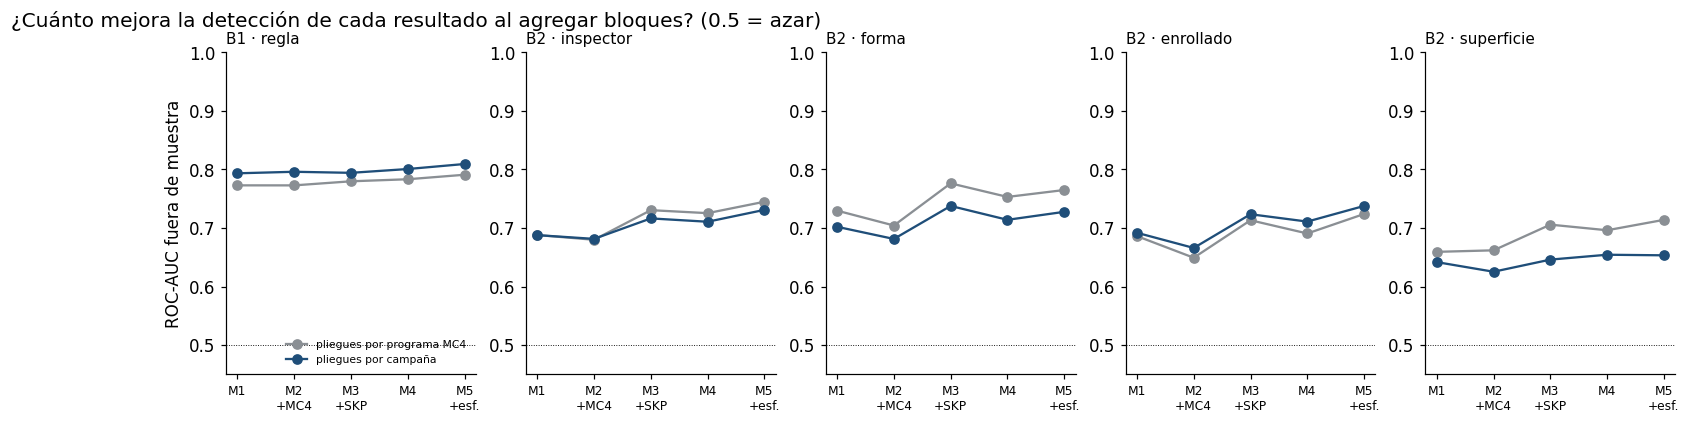

In [6]:
fig, ax = plt.subplots(1, len(RESULT), figsize=(17, 3.8), sharey=False)
for a, r in zip(ax, RESULT.values()):
    t = tab[tab.resultado == r]
    for val, c in [('programa MC4', COLORES['gris']), ('campaña', COLORES['azul'])]:
        tt = t[t['validación'] == val]
        a.plot(range(len(tt)), tt['ROC-AUC'], 'o-', color=c, label=f'pliegues por {val}')
    a.axhline(.5, color='k', lw=.6, ls=':')
    a.set_xticks(range(len(MODELOS))); a.set_xticklabels(['M1', 'M2\n+MC4', 'M3\n+SKP', 'M4', 'M5\n+esf.'], fontsize=8)
    a.set_title(r, fontsize=10); a.set_ylim(.45, 1)
ax[0].set_ylabel('ROC-AUC fuera de muestra'); ax[0].legend(fontsize=7, loc='lower right')
fig.suptitle('¿Cuánto mejora la detección de cada resultado al agregar bloques? (0.5 = azar)', x=.01, ha='left')
guardar(fig, '05_anidados_auc'); plt.show()

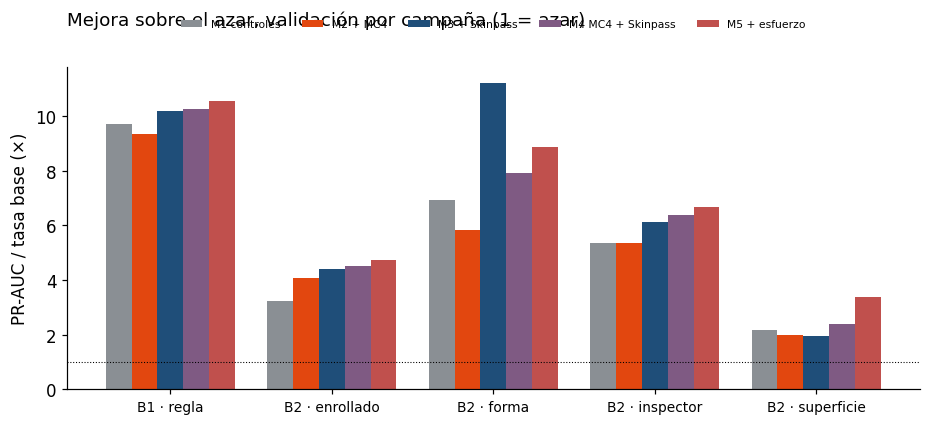

modelo,M1 controles,M2 + MC4,M3 + Skinpass,M4 MC4 + Skinpass,M5 + esfuerzo
resultado,,,,,
B1 · regla,9.70,9.34,10.21,10.26,10.54
B2 · enrollado,3.22,4.06,4.39,4.50,4.75
B2 · forma,6.91,5.85,11.22,7.93,8.88
B2 · inspector,5.36,5.35,6.14,6.40,6.69
B2 · superficie,2.18,1.99,1.96,2.40,3.37


In [7]:
# Mejora sobre el azar (PR-AUC / tasa base), validación por campaña.
piv = tab[tab['validación'] == 'campaña'].pivot(index='resultado', columns='modelo', values='mejora sobre azar ×')[list(MODELOS)]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(piv)); w = .16
cols_m = [COLORES['gris'], COLORES['naranja'], COLORES['azul'], '#7f5a83', COLORES['rojo']]
for i, (m, c) in enumerate(zip(piv.columns, cols_m)):
    ax.bar(x + (i - 2) * w, piv[m], w, color=c, label=m)
ax.axhline(1, color='k', lw=.7, ls=':'); ax.set_xticks(x); ax.set_xticklabels(piv.index, fontsize=9)
ax.set_ylabel('PR-AUC / tasa base (×)'); ax.legend(fontsize=7, ncol=5, loc='upper center', bbox_to_anchor=(.5, 1.18))
ax.set_title('Mejora sobre el azar, validación por campaña (1 = azar)', pad=28)
guardar(fig, '05_mejora_azar'); plt.show()
piv.round(2)

### 2. Regresión logística para defectos de forma
Probamos la hipótesis del Notebook 02 con un modelo interpretable. Las variables continuas se **centran por producto** y se estandarizan; el producto entra como su **tasa histórica de forma**, calculada fuera de pliegue. Se reportan odds ratios por desviación estándar, con intervalos robustos agrupados por programa del MC4.

In [8]:
VARS_LOG = ['corona_relativa_pct', 'acunamiento_um', 'canteo_r1', 'error_t_enrollado_c', 'caida_f1_f7_c', 'dias_mc4_skp',
            'piezas_en_campana', 'corona_rodillo', 'diametro_rodillo_mm', 'fuerza_real', 'bending_real', 'espesor_mm', 'ancho_mm']
lg = d[['producto', 'programa_mc4', 'b2_forma', 'modo_fuerza'] + VARS_LOG].copy()
lg[VARS_LOG] = lg[VARS_LOG].fillna(lg.groupby('producto', observed=True)[VARS_LOG].transform('median')).fillna(lg[VARS_LOG].median())
lg[VARS_LOG] = lg[VARS_LOG] - lg.groupby('producto', observed=True)[VARS_LOG].transform('mean')
lg[VARS_LOG] = lg[VARS_LOG] / lg[VARS_LOG].std()
# tasa histórica del producto, fuera de pliegue y suavizada hacia la tasa global
tasa_prod = np.full(len(lg), np.nan); glob = lg['b2_forma'].mean(); k_suav = 50
for k in range(5):
    tr, va = pl_mc4 != k, pl_mc4 == k
    g_ = lg.loc[tr].groupby('producto', observed=True)['b2_forma'].agg(['sum', 'size'])
    suav = (g_['sum'] + k_suav * glob) / (g_['size'] + k_suav)
    tasa_prod[va] = lg.loc[va, 'producto'].map(suav).astype(float).fillna(glob).values
lg['logit_tasa_producto'] = np.log(tasa_prod / (1 - tasa_prod))

Xl = sm.add_constant(lg[VARS_LOG + ['modo_fuerza', 'logit_tasa_producto']])
logit = sm.Logit(lg['b2_forma'], Xl).fit(disp=0, cov_type='cluster', cov_kwds={'groups': pd.factorize(lg['programa_mc4'])[0]})
ci = logit.conf_int()
OR = pd.DataFrame({'odds ratio': np.exp(logit.params), 'IC bajo': np.exp(ci[0]), 'IC alto': np.exp(ci[1]), 'p': logit.pvalues}).drop('const')
OR.round(3).to_csv(RESULTADOS / '05_logistica_forma.csv')
OR.round(2)

,odds ratio,IC bajo,IC alto,p
corona_relativa_pct,1.09,0.94,1.26,0.26
acunamiento_um,0.90,0.78,1.05,0.17
canteo_r1,0.77,0.59,1.01,0.06
error_t_enrollado_c,1.02,0.77,1.36,0.88
caida_f1_f7_c,1.00,0.82,1.22,0.99
dias_mc4_skp,1.16,0.99,1.37,0.07
piezas_en_campana,0.90,0.75,1.08,0.27
corona_rodillo,1.35,1.06,1.72,0.01
diametro_rodillo_mm,1.03,0.84,1.26,0.77
fuerza_real,1.31,1.09,1.58,0.00


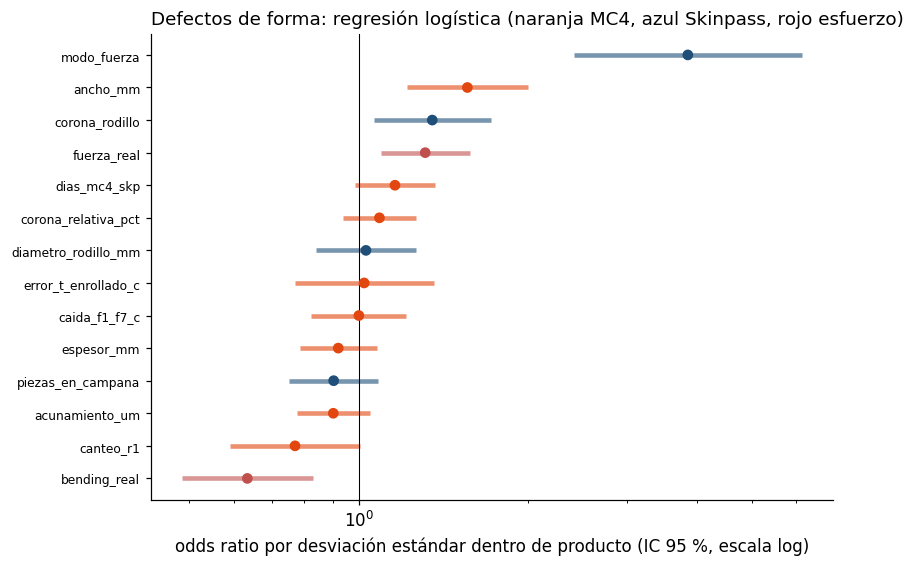

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.5))
o = OR.drop(['logit_tasa_producto']).sort_values('odds ratio')
y = np.arange(len(o))
col = [COLORES['rojo'] if v in ['fuerza_real', 'bending_real'] else (COLORES['azul'] if v in ['piezas_en_campana', 'corona_rodillo', 'diametro_rodillo_mm', 'modo_fuerza'] else COLORES['naranja']) for v in o.index]
ax.hlines(y, o['IC bajo'], o['IC alto'], color=col, lw=3, alpha=.6); ax.scatter(o['odds ratio'], y, color=col, zorder=3)
ax.axvline(1, color='k', lw=.7); ax.set_xscale('log')
ax.set_yticks(y); ax.set_yticklabels(o.index, fontsize=8)
ax.set_xlabel('odds ratio por desviación estándar dentro de producto (IC 95 %, escala log)')
ax.set_title('Defectos de forma: regresión logística (naranja MC4, azul Skinpass, rojo esfuerzo)')
guardar(fig, '05_logistica_forma'); plt.show()

### 3. Forma de la relación: fuerza real y defectos de forma

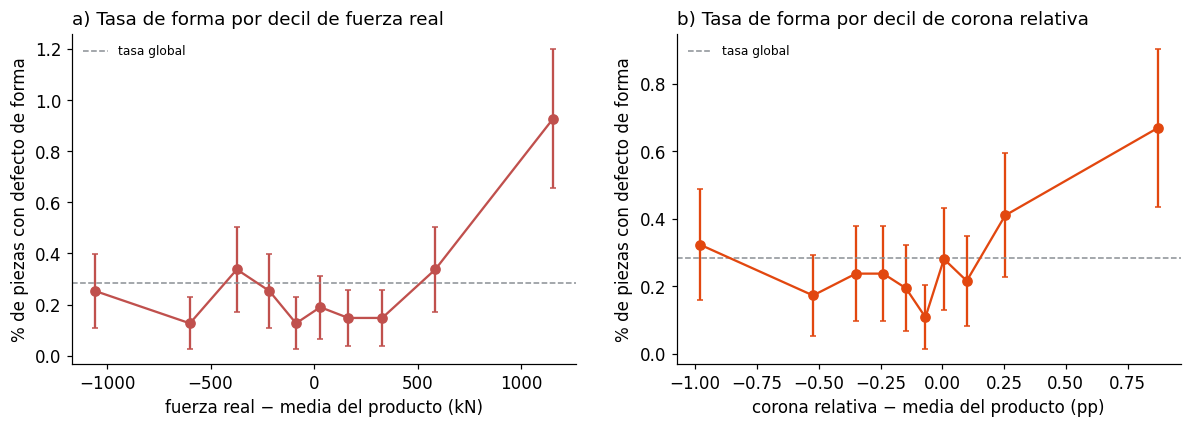

In [10]:
fr = d[['producto', 'fuerza_real', 'corona_relativa_pct', 'b2_forma']].dropna(subset=['fuerza_real']).copy()
for c in ['fuerza_real', 'corona_relativa_pct']:
    fr[c + '_d'] = fr[c] - fr.groupby('producto', observed=True)[c].transform('mean')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
for a, c, nom in [(ax[0], 'fuerza_real_d', 'fuerza real − media del producto (kN)'), (ax[1], 'corona_relativa_pct_d', 'corona relativa − media del producto (pp)')]:
    s = fr.dropna(subset=[c])
    q = pd.qcut(s[c].rank(method='first'), 10, labels=False)
    g_ = s.groupby(q).agg(x=(c, 'median'), tasa=('b2_forma', 'mean'), n=('b2_forma', 'size'))
    se = np.sqrt(g_.tasa * (1 - g_.tasa) / g_.n)
    a.errorbar(g_.x, 100 * g_.tasa, yerr=196 * se, fmt='o-', color=COLORES['rojo'] if 'fuerza' in c else COLORES['naranja'], capsize=2)
    a.axhline(100 * s['b2_forma'].mean(), color=COLORES['gris'], ls='--', lw=1, label='tasa global')
    a.set_xlabel(nom); a.set_ylabel('% de piezas con defecto de forma'); a.legend(fontsize=8)
ax[0].set_title('a) Tasa de forma por decil de fuerza real'); ax[1].set_title('b) Tasa de forma por decil de corona relativa')
guardar(fig, '05_forma_deciles'); plt.show()

### 4. Operador y defectos (O/E dentro de producto)

In [11]:
op = {RESULT[r]: oe(d, r, 'usuario_skp') for r in ['b1', 'b2', 'b2_forma', 'b2_enrollado', 'b2_superficie_manejo']}
piezas_op = op['B1 · regla']['piezas']
grandes = piezas_op[piezas_op >= 500].index
ord_db = d.assign(db=d['delta_bending'] - d.groupby('producto', observed=True)['delta_bending'].transform('mean')) \
          .groupby('usuario_skp', observed=True)['db'].mean().loc[grandes].sort_values()
alias = {u: f'Operador {i + 1}' for i, u in enumerate(ord_db.index)}     # mismo orden que en el Notebook 04 (por ΔBending)
t_op = pd.DataFrame({k: v.loc[grandes, 'O/E'] for k, v in op.items()})
t_op.insert(0, 'ΔBending medio (dentro)', ord_db)
t_op.insert(0, 'piezas', piezas_op.loc[grandes])
t_op = t_op.loc[ord_db.index].rename(index=alias)
t_op.round(2).to_csv(RESULTADOS / '05_operador_oe.csv')
t_op.round(2)

,piezas,ΔBending medio (dentro),B1 · regla,B2 · inspector,B2 · forma,B2 · enrollado,B2 · superficie
usuario_skp,,,,,,,
Operador 1,7457,-97.82,0.82,1.50,0.56,2.01,1.30
Operador 2,5337,-77.77,1.16,1.04,0.76,1.28,0.93
Operador 3,10429,24.03,1.05,1.06,2.07,0.48,1.17
Operador 4,5077,30.08,0.90,0.99,0.29,0.94,1.53
Operador 5,7605,32.79,0.94,0.51,0.80,0.61,0.08
Operador 6,6647,32.80,1.03,0.96,1.38,0.75,1.11
Operador 7,4054,55.43,1.25,0.96,0.37,1.32,1.03


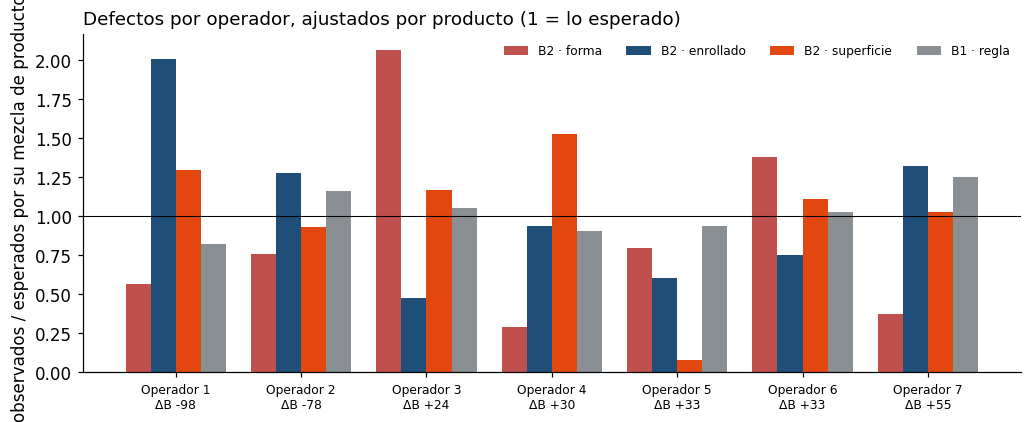

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
cols_o = ['B2 · forma', 'B2 · enrollado', 'B2 · superficie', 'B1 · regla']
x = np.arange(len(t_op)); w = .2
for i, (c, col) in enumerate(zip(cols_o, [COLORES['rojo'], COLORES['azul'], COLORES['naranja'], COLORES['gris']])):
    ax.bar(x + (i - 1.5) * w, t_op[c], w, color=col, label=c)
ax.axhline(1, color='k', lw=.7)
ax.set_xticks(x); ax.set_xticklabels([f'{i}\nΔB {v:+.0f}' for i, v in zip(t_op.index, t_op['ΔBending medio (dentro)'])], fontsize=8)
ax.set_ylabel('observados / esperados por su mezcla de productos'); ax.legend(fontsize=8, ncol=4)
ax.set_title('Defectos por operador, ajustados por producto (1 = lo esperado)')
guardar(fig, '05_operador_oe'); plt.show()

### 5. Administrativa: el tamaño de la oportunidad de la intervención A
En el Notebook 01, los rollos que excedían el peso máximo de la orden y no se dividieron se retuvieron por PESO (+) en el 51 % de los casos. Estimamos cuánto se habría evitado si esos rollos se hubieran dividido, suponiendo que les iría como a los que sí se dividieron.

In [13]:
grupo = np.select([(d.excede_peso_orden == 1) & (d.dividido == 0), (d.excede_peso_orden == 1) & (d.dividido == 1)],
                  ['Excede y NO se divide', 'Excede y se divide'], 'Cabe en la orden')
ga = d.assign(grupo=grupo, t=d['peso_entrada_t'] / d.groupby('rollo')['rollo'].transform('size'))
tA = ga.groupby('grupo').agg(piezas=('ret_peso_mas', 'size'), ret_peso_mas=('ret_peso_mas', 'sum'), tasa=('ret_peso_mas', 'mean'))
tasa_div = tA.loc['Excede y se divide', 'tasa']
nodiv = ga[ga.grupo == 'Excede y NO se divide']
evitables = nodiv['ret_peso_mas'].sum() - tasa_div * len(nodiv)
ton_ev = (nodiv.loc[nodiv.ret_peso_mas == 1, 't'].sum()) * (1 - tasa_div / nodiv['ret_peso_mas'].mean())
total_admin = d['administrativa'].sum()
print(f"Retenciones por PESO (+) en rollos que exceden y no se dividen: {int(nodiv['ret_peso_mas'].sum())} de {len(nodiv)} piezas")
print(f"Evitables si se dividieran (con la tasa de los que sí se dividen, {100 * tasa_div:.1f} %): ~{evitables:.0f} piezas, ~{ton_ev:,.0f} t")
print(f"Eso es ~{100 * evitables / total_admin:.0f} % de las {total_admin} retenciones administrativas y "
      f"~{100 * evitables / d['retenida'].sum():.0f} % de todas las retenidas del periodo de entrenamiento (enero-octubre)")
tA.assign(tasa=lambda t: (100 * t.tasa).round(1))

Retenciones por PESO (+) en rollos que exceden y no se dividen: 798 de 1638 piezas
Evitables si se dividieran (con la tasa de los que sí se dividen, 0.3 %): ~793 piezas, ~19,677 t
Eso es ~51 % de las 1566 retenciones administrativas y ~24 % de todas las retenidas del periodo de entrenamiento (enero-octubre)


,piezas,ret_peso_mas,tasa
grupo,,,
Cabe en la orden,31823,6,0.0
Excede y NO se divide,1638,798,48.7
Excede y se divide,14000,46,0.3


**Advertencia.** Es una estimación optimista: supone que esos rollos **podían** dividirse (que las piezas resultantes cabían en el peso mínimo de la orden y en la longitud permitida). Algunos quizá no se dividieron por una buena razón. Aun así da el orden de magnitud de la oportunidad, y el piloto de la intervención A lo mediría directamente.

## E. Interpretación de los resultados

**1. Una trampa más, corregida: B1 y sus propias mediciones.** Con el error de ancho, el de espesor y el de enrollado como predictores, B1 parecía muy predecible (mejora sobre el azar 16×, ROC-AUC 0.86) y el MC4 parecía aportar mucho. Esas mediciones son las que **definen** la regla que retiene la pieza: el modelo reaprendía la regla. Sin ellas, la mejora cae a 9× y **el MC4 no agrega nada** (M2: 9.3× contra M1: 9.7×).

**2. Lo que se predice de B1 lo predicen el producto y las dimensiones.** M1 ya da ROC-AUC 0.79. Agregar Skinpass (+0.5×) y esfuerzo (+0.3×) mejora poco. B1 es sobre todo **qué producto y qué orden**: tolerancias estrechas fallan más.

**3. Los defectos de inspector (B2) son difíciles de predecir.** El mejor modelo llega a ROC-AUC 0.73 y apenas mejora sobre el azar (6.7×, contra 5.4× de los controles). **El MC4 no aporta** en ninguna familia con validación por campaña (B2 total: 5.36× → 5.35×).

**4. Forma: lo que sí aporta es el Skinpass, no el MC4.**
- GBDT: el bloque Skinpass sube la mejora sobre el azar de 6.9× a **11.2×**; agregar el MC4 la **baja** a 7.9× (ruido).
- Regresión logística, dentro de producto (odds ratio por desviación estándar):
  - **Modo Fuerza: 3.85** (IC 2.4-6.1).
  - **Ancho: 1.56**.
  - **Corona del rodillo: 1.35**.
  - **Fuerza real: 1.31**.
  - **Bending real: 0.63**: más bending, menos defectos de forma.
  - Corona relativa del MC4: 1.09, **no distinguible de 1**.
- Por deciles: la tasa de forma se dispara en el **10 % de piezas con más fuerza real** que lo normal para su producto (0.9 % contra ~0.2 %). También sube en el 10 % con **más corona** (0.7 %), pero esa cola no la recoge un modelo lineal ni mejora la predicción fuera de muestra.

**5. El modo Fuerza (RCO) concentra los defectos.** Comparado con lo que su mezcla de productos haría esperar, el modo Fuerza tiene **7.9 veces** más defectos de forma, 3.3 veces más de superficie y 2.3 veces más defectos de inspector. *Cuidado:* el modo se elige por pieza y no sabemos con qué criterio. Si el operador pasa a modo Fuerza justo cuando el rollo llega con mala forma, el modo sería consecuencia y no causa (selección).

**6. El operador no muestra un patrón claro en defectos.** Las razones O/E por operador van de 0.3 a 2.1 según la familia, sin relación con su práctica de bending. Los dos operadores de ΔBending bajo (Notebook 04) no tienen sistemáticamente más ni menos defectos de forma (O/E 0.56 y 0.76). Con pocos eventos por operador, el ruido domina. **La intervención E no tiene, por ahora, evidencia de impacto en la calidad.**

**7. La intervención A tiene la oportunidad más grande y mejor medida.** En enero-octubre, los rollos que excedían el peso máximo de la orden y **no se dividieron** se retuvieron por PESO (+) en el 48.7 % de los casos, contra 0.3 % si se dividían. Dividirlos habría evitado ~**790 retenciones (~19,700 t)**: la mitad de las retenciones administrativas y ~24 % de todas las retenidas del periodo. Es una estimación optimista (supone que se podían dividir), pero el orden de magnitud supera por mucho a cualquier otro resultado.

## F. Conclusiones de la etapa

### Respuesta a la pregunta de la tesis (parte B)
> **Una vez controlado por producto, la herencia del MC4 no mejora la predicción de las retenciones por defecto físico**, ni de las de regla (B1) ni de las de inspector (B2), con validación por campaña. Lo que se asocia con los defectos de forma está **en el Skinpass**: el modo de operación, la fuerza real alta, el bending bajo y la corona del rodillo. Las retenciones más numerosas y evitables no son físicas: son **de asignación de peso**.

### Hallazgos principales
1. **B1 con sus propias mediciones es una tautología** (16× contra 9×); sin ellas, el MC4 no aporta.
2. **B2 se predice poco** (ROC-AUC ≤ 0.74); el MC4 no aporta en ninguna familia.
3. **Forma:** se asocia con modo Fuerza (OR 3.9), fuerza real alta (OR 1.3; tasa ×4 en el decil superior), bending bajo (OR 0.63) y corona del rodillo (OR 1.35). La corona del MC4 solo en su cola, sin generalizar.
4. **Modo Fuerza:** 7.9 veces más defectos de forma de lo esperado, a revisar como posible selección.
5. **Operador:** sin patrón claro en defectos; la intervención E queda sin evidencia de calidad.
6. **Intervención A:** ~790 retenciones y ~19,700 t evitables en diez meses.

### Decisiones tomadas
| Tema | Decisión |
|---|---|
| B1 | Nunca usar como predictor la medición que define la regla |
| Mediador para el Notebook 06 | Fuerza real y bending real para la familia forma; el primer eslabón (MC4 → fuerza) es débil |
| Modo Fuerza | Tratarlo como posible selección; en el Notebook 06, analizar forma dentro del modo Elongación también |
| Intervenciones | A gana fuerza; B y E pierden fuerza para calidad; D sigue sin evidencia de calidad |

### Limitaciones
- Pocos eventos de B2 por familia (136 de forma en entrenamiento): intervalos anchos.
- El modo de operación y el operador no se asignan al azar.
- La estimación de la intervención A supone que los rollos podían dividirse.

### Qué sigue
El **Notebook 06** prueba formalmente la cadena **MC4 → esfuerzo → defecto de forma** (mediación) y estima con Double ML el efecto de las variables del Skinpass que se asocian con forma, con sus supuestos explícitos.